# CardioScope: end-to-end heart disease risk project

One notebook that holds the whole project: **data → EDA → preprocessing → four models (including an ANN) → cross-validation → evaluation → explanations → saved artifacts → Streamlit dashboard**.

| Part | What it does |
|---|---|
| How it works / Glossary | pipeline in plain words; abbreviations and column meanings |
| 1. Setup | imports, constants, colour palette |
| 2. Data collection | load the Framingham CSV, audit quality |
| 3. EDA | colourful plots of missing data, outcome, distributions, risk factors, correlations |
| 4. Preprocessing | leakage-safe imputation and scaling, stratified split |
| 5. Models | Logistic Regression, Random Forest, XGBoost, PyTorch ANN |
| 6. Validation | 5-fold cross-validation, threshold tuning, held-out test |
| 6b. Final results | side-by-side comparison and verdict on the four models |
| 7. Evaluation | ROC, PR, calibration, confusion matrix, importance, ANN curves |
| 8. Explanations | per-patient "what moves this risk" |
| 9. Artifacts | portable files the dashboard reads, plus a round-trip check |
| 10. Dashboard | writes `streamlit_app.py`; launch with `streamlit run streamlit_app.py` |

**How to run:** place `framingham.csv` in `data/raw/`, then *Run All*. Needs `numpy pandas scikit-learn xgboost torch matplotlib seaborn streamlit plotly`.

## Project overview

### Problem statement
Cardiovascular disease is the leading cause of death worldwide, and coronary heart disease is a major part of it. Clinicians need a quick, explainable estimate of a patient's 10-year risk from routine measurements so that prevention can be targeted. The problem is binary classification: given 15 recorded risk factors, predict whether a patient develops CHD within ten years (TenYearCHD). Only about one patient in seven has the outcome, and some measurements are missing, so the project must handle class imbalance and gaps carefully.

### Motivation
Early identification of high-risk people lets lifestyle change and treatment start sooner. Established risk scores exist, but a transparent machine-learning pipeline with a clear comparison of model types, honest validation and per-patient explanations shows what modern methods add and where they do not.

### Objectives
1. Build a 10-year coronary heart disease (CHD) risk predictor from the Framingham cohort using classical machine learning and an artificial neural network.
2. Prepare the data without leakage: stratified split first, then imputation and scaling learned from the training data only.
3. Compare four models (logistic regression, random forest, XGBoost, ANN) with 5-fold cross-validation and one final held-out test.
4. Choose the decision threshold with Youden's J and judge models on AUC, sensitivity, specificity, precision, F1 and calibration.
5. Explain each prediction to the user and deliver everything in an interactive Streamlit dashboard.

### Scope
In scope: the public Framingham extract of about 4,240 patients, four models, cross-validation, threshold selection, explanations and a dashboard. Out of scope: clinical validation, other populations, imaging or genetic data, and any use for real diagnosis.

### Background
The Framingham Heart Study began in 1948 and established many of today's cardiovascular risk factors [1]. Its risk equations remain a standard reference for primary-care risk estimation [2]. This project asks how far standard machine-learning models, random forest [3], gradient boosting [4] and a small neural network [6][7], go on the same kind of data, using scikit-learn [5] and judging them with ROC-AUC [9], precision-recall [10] and Youden's threshold [8]. The numbered sources are listed under References at the end of the notebook.


## Literature review and background

**Origins of risk-factor thinking.** The Framingham Heart Study began in 1948 and gave medicine the idea that heart disease can be predicted from ordinary measurements such as blood pressure, cholesterol and smoking (Dawber et al., 1951 [1]). It is still the standard source for risk-prediction work, which is why this project uses its extract.

**Conventional risk scores.** D'Agostino et al. (2008) [2] turned the cohort into a general cardiovascular risk profile for primary care that combines age, sex, cholesterol, blood pressure, treatment, smoking and diabetes in a regression-based score. It is transparent and easy to use, but it assumes each factor acts in a fixed, mostly additive way.

**Machine-learning alternatives.** Random forests (Breiman, 2001 [3]) average many decision trees and can capture interactions without assuming a form. Gradient-boosted trees such as XGBoost (Chen and Guestrin, 2016 [4]) build trees one after another to correct earlier errors and are strong on tabular data. Neural networks trained with modern optimisers such as AdamW (Loshchilov and Hutter, 2019 [7]) add flexibility at the cost of interpretability. Implementations used here are scikit-learn [5] and PyTorch [6].

**Evaluating a risk model.** Because only about one patient in seven has the outcome, accuracy is misleading. The area under the ROC curve (Hanley and McNeil, 1982 [9]) measures ranking quality, precision-recall analysis (Saito and Rehmsmeier, 2015 [10]) is more informative for the rare class, and Youden's index (1950 [8]) gives a principled decision threshold.

**Gap this project addresses.** Rather than claim that a complex model is better, CardioScope compares a linear model, two tree ensembles and a neural network under identical, leakage-free preprocessing and validation, reports calibration and the threshold trade-off, and explains each individual prediction.

## How it works

**1. Collect** Load the Framingham Heart Study extract (about 4,240 patients, 15 risk factors, outcome `TenYearCHD`) and audit missing values and duplicates.
**2. Split** Hold out 20% of patients as a locked test set, keeping the same CHD rate in both parts (stratified).
**3. Clean** Impute gaps and standardise numeric columns. Everything is learned from the training split only, and refit inside every CV fold, so nothing leaks.
**4. Train** Fit four pipelines: logistic regression, random forest, XGBoost and a PyTorch ANN. No class weighting, so probabilities stay interpretable.
**5. Validate** 5-fold cross-validation gives out-of-fold predictions. The threshold maximises Youden's J on them, and the served model is chosen by CV AUC alone.
**6. Test** Each model is scored once on the untouched test set, which is the honest final check.
**7. Explain** For one patient each factor is swapped to a typical value to show what pushes risk up or down.
**8. Serve** Portable artifacts (weights and preprocessing parameters as JSON/CSV) are read by this dashboard, which needs no custom classes.


## Workflow and system architecture

The pipeline from raw data to dashboard. Each box is one stage, and only the first two touch the raw rows before the train/test split.

In [ ]:
# Workflow and system architecture diagram
import matplotlib.patches as mpatches
steps = [("framingham.csv\n4,240 patients", "#4361ee"), ("Stratified split\n80% train / 20% test", "#7209b7"), ("Preprocessing\nimpute + flag + scale\n(train only)", "#f72585"),
         ("4 models\nLR · RF · XGBoost · ANN", "#fb8500"), ("5-fold CV\nAUC + Youden threshold", "#2a9d8f"), ("Held-out test\nmetrics + plots", "#4cc9f0"),
         ("Saved artifacts\nJSON / CSV / weights", "#ffbe0b"), ("Streamlit\ndashboard", "#e5383b")]
fig, ax = plt.subplots(figsize=(17, 3.2)); ax.axis("off"); ax.set_xlim(0, len(steps) * 2.1); ax.set_ylim(0, 2)
for i, (t, c) in enumerate(steps):
    x = i * 2.1 + .05
    ax.add_patch(mpatches.FancyBboxPatch((x, .4), 1.8, 1.2, boxstyle="round,pad=0.03", fc=c, ec="white", alpha=.9))
    ax.text(x + .9, 1.0, t, ha="center", va="center", color="white", fontsize=8.6, fontweight="bold")
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 2.08, 1.0), xytext=(x + 1.84, 1.0), arrowprops=dict(arrowstyle="->", lw=2, color="#555"))
plt.title("CardioScope workflow: data to dashboard", fontweight="bold"); plt.show()

## Glossary

### Abbreviations and terms

| Abbreviation | Stands for | Meaning |
|---|---|---|
| CHD | Coronary heart disease | Narrowing of the arteries that feed the heart muscle; the outcome we predict. |
| ANN / MLP | Artificial neural network / multilayer perceptron | A small network of layers of weighted units that learns non-linear patterns. |
| XGBoost | Extreme gradient boosting | Many small decision trees built one after another, each fixing the last one's errors. |
| RF | Random forest | Many decision trees trained on random subsets whose votes are averaged. |
| LR | Logistic regression | A linear model that turns a weighted sum of factors into a probability. |
| CV | Cross-validation | Splitting the training data into folds, training on some and scoring on the rest, to estimate performance fairly. |
| AUC / ROC-AUC | Area under the ROC curve | Chance that a random CHD patient gets a higher risk than a random healthy one. 0.5 = coin flip, 1.0 = perfect. |
| PR-AUC | Area under the precision-recall curve | Like AUC but focused on the rare positive class; useful when CHD is uncommon. |
| Sensitivity / Recall | True-positive rate | Share of people who develop CHD that the model flags. |
| Specificity | True-negative rate | Share of healthy people the model correctly leaves unflagged. |
| Precision | Positive predictive value | Of the people flagged, the share who really develop CHD. |
| F1 | F1 score | Harmonic mean of precision and recall. |
| Youden's J | Sensitivity + specificity - 1 | Used to pick the threshold that best balances catching cases against false alarms. |
| Threshold | Decision cut-off | Predicted risk above which a person is flagged for follow-up. |
| TP / FP / TN / FN | Confusion-matrix cells | True/false positives and negatives: correct flags, false alarms, correct all-clears, missed cases. |
| Brier score | Probability error | Mean squared gap between predicted risk and outcome. Lower is better. |
| Calibration | Probability honesty | Whether 20% predicted risk really means about 20 in 100 develop CHD. |
| Data leakage | Test information leaking into training | Avoided by learning medians and scaling from training data only. |
| Imputation | Filling missing values | Median for numbers, mode for categories, plus a missing-glucose flag. |

### Dataset columns

| Column | Meaning | Detail |
|---|---|---|
| male | Sex | 1 = male, 0 = female |
| age | Age | Age in years at the first exam |
| education | Education level | 1 = some high school ... 4 = college or above |
| currentSmoker | Current smoker | 1 = smokes now |
| cigsPerDay | Cigarettes per day | Average cigarettes smoked daily |
| BPMeds | Blood-pressure medication | 1 = on BP medication |
| prevalentStroke | Prior stroke | 1 = has had a stroke |
| prevalentHyp | Hypertension | 1 = diagnosed with high blood pressure |
| diabetes | Diabetes | 1 = diabetic |
| totChol | Total cholesterol | mg/dL |
| sysBP | Systolic blood pressure | Pressure when the heart beats, mmHg |
| diaBP | Diastolic blood pressure | Pressure between beats, mmHg |
| BMI | Body mass index | Weight (kg) / height (m) squared |
| heartRate | Resting heart rate | Beats per minute |
| glucose | Blood glucose | mg/dL |
| TenYearCHD | Outcome (target) | 1 = coronary heart disease within 10 years |


In [ ]:
# Glossary and step text, shared word-for-word with the Streamlit dashboard
FEATURE_GLOSSARY = [
    ("male", "Sex", "1 = male, 0 = female"), ("age", "Age", "Age in years at the first exam"),
    ("education", "Education level", "1 = some high school ... 4 = college or above"),
    ("currentSmoker", "Current smoker", "1 = smokes now"), ("cigsPerDay", "Cigarettes per day", "Average cigarettes smoked daily"),
    ("BPMeds", "Blood-pressure medication", "1 = on BP medication"), ("prevalentStroke", "Prior stroke", "1 = has had a stroke"),
    ("prevalentHyp", "Hypertension", "1 = diagnosed with high blood pressure"), ("diabetes", "Diabetes", "1 = diabetic"),
    ("totChol", "Total cholesterol", "mg/dL"), ("sysBP", "Systolic blood pressure", "Pressure when the heart beats, mmHg"),
    ("diaBP", "Diastolic blood pressure", "Pressure between beats, mmHg"), ("BMI", "Body mass index", "Weight (kg) / height (m) squared"),
    ("heartRate", "Resting heart rate", "Beats per minute"), ("glucose", "Blood glucose", "mg/dL"),
    ("TenYearCHD", "Outcome (target)", "1 = coronary heart disease within 10 years"),
]
TERM_GLOSSARY = [
    ("CHD", "Coronary heart disease", "Narrowing of the arteries that feed the heart muscle; the outcome we predict."),
    ("ANN / MLP", "Artificial neural network / multilayer perceptron", "A small network of layers of weighted units that learns non-linear patterns."),
    ("XGBoost", "Extreme gradient boosting", "Many small decision trees built one after another, each fixing the last one's errors."),
    ("RF", "Random forest", "Many decision trees trained on random subsets whose votes are averaged."),
    ("LR", "Logistic regression", "A linear model that turns a weighted sum of factors into a probability."),
    ("CV", "Cross-validation", "Splitting the training data into folds, training on some and scoring on the rest, to estimate performance fairly."),
    ("AUC / ROC-AUC", "Area under the ROC curve", "Chance that a random CHD patient gets a higher risk than a random healthy one. 0.5 = coin flip, 1.0 = perfect."),
    ("PR-AUC", "Area under the precision-recall curve", "Like AUC but focused on the rare positive class; useful when CHD is uncommon."),
    ("Sensitivity / Recall", "True-positive rate", "Share of people who develop CHD that the model flags."),
    ("Specificity", "True-negative rate", "Share of healthy people the model correctly leaves unflagged."),
    ("Precision", "Positive predictive value", "Of the people flagged, the share who really develop CHD."),
    ("F1", "F1 score", "Harmonic mean of precision and recall."),
    ("Youden's J", "Sensitivity + specificity - 1", "Used to pick the threshold that best balances catching cases against false alarms."),
    ("Threshold", "Decision cut-off", "Predicted risk above which a person is flagged for follow-up."),
    ("TP / FP / TN / FN", "Confusion-matrix cells", "True/false positives and negatives: correct flags, false alarms, correct all-clears, missed cases."),
    ("Brier score", "Probability error", "Mean squared gap between predicted risk and outcome. Lower is better."),
    ("Calibration", "Probability honesty", "Whether 20% predicted risk really means about 20 in 100 develop CHD."),
    ("Data leakage", "Test information leaking into training", "Avoided by learning medians and scaling from training data only."),
    ("Imputation", "Filling missing values", "Median for numbers, mode for categories, plus a missing-glucose flag."),
]
HOW_STEPS = [
    ("1. Collect", "Load the Framingham Heart Study extract (about 4,240 patients, 15 risk factors, outcome `TenYearCHD`) and audit missing values and duplicates."),
    ("2. Split", "Hold out 20% of patients as a locked test set, keeping the same CHD rate in both parts (stratified)."),
    ("3. Clean", "Impute gaps and standardise numeric columns. Everything is learned from the training split only, and refit inside every CV fold, so nothing leaks."),
    ("4. Train", "Fit four pipelines: logistic regression, random forest, XGBoost and a PyTorch ANN. No class weighting, so probabilities stay interpretable."),
    ("5. Validate", "5-fold cross-validation gives out-of-fold predictions. The threshold maximises Youden's J on them, and the served model is chosen by CV AUC alone."),
    ("6. Test", "Each model is scored once on the untouched test set, which is the honest final check."),
    ("7. Explain", "For one patient each factor is swapped to a typical value to show what pushes risk up or down."),
    ("8. Serve", "Portable artifacts (weights and preprocessing parameters as JSON/CSV) are read by this dashboard, which needs no custom classes."),
]

## 1. Setup

In [1]:
import json, platform, warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import xgboost
from IPython.display import display
from torch import nn
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
torch.set_num_threads(2)

# ---- configuration ------------------------------------------------------------------
SEED, TEST_SIZE, CV_FOLDS = 42, 0.2, 5
ROOT = Path.cwd()
RAW_CSV = ROOT / "data" / "raw" / "framingham.csv"
ART = ROOT / "artifacts"
(ART / "models").mkdir(parents=True, exist_ok=True)

TARGET = "TenYearCHD"
FEATURES = ["male", "age", "education", "currentSmoker", "cigsPerDay", "BPMeds", "prevalentStroke",
            "prevalentHyp", "diabetes", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
CONTINUOUS = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
BINARY = ["male", "currentSmoker", "BPMeds", "prevalentStroke", "prevalentHyp", "diabetes"]
ORDINAL = ["education"]
RISK_BANDS = {"low_below": 0.10, "high_from": 0.20}   # 10-year CHD probability bands
DISCLAIMER = ("Educational project built on the Framingham cohort. Not a medical device and "
              "not a substitute for clinical judgement.")

# ---- colours (used by every plot) ---------------------------------------------------
MODEL_COLORS = {"Logistic Regression": "#4361ee", "Random Forest": "#2a9d8f",
                "XGBoost": "#fb8500", "ANN (MLP)": "#e5383b"}
OUTCOME_COLORS = ["#4cc9f0", "#f72585"]   # no CHD, CHD
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
print("torch", torch.__version__, "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__)

torch 2.15.0+cu132 | sklearn 1.9.1 | xgboost 3.4.1


## 2. Data collection

The Framingham Heart Study extract: 4,240 patients, 15 risk factors, and the outcome `TenYearCHD` (coronary heart disease within ten years).

In [2]:
df = pd.read_csv(RAW_CSV).drop_duplicates().reset_index(drop=True).apply(pd.to_numeric, errors="coerce")
print(f"{df.shape[0]:,} patients x {df.shape[1]} columns | CHD rate {df[TARGET].mean():.1%}")
display(df.head())
display(df.describe().T.round(2).style.background_gradient(cmap="YlGnBu", subset=["mean", "50%"]))

4,240 patients x 16 columns | CHD rate 15.2%


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


,count,mean,std,min,25%,50%,75%,max
male,4240.000000,0.430000,0.500000,0.000000,0.000000,0.000000,1.000000,1.000000
age,4240.000000,49.580000,8.570000,32.000000,42.000000,49.000000,56.000000,70.000000
education,4135.000000,1.980000,1.020000,1.000000,1.000000,2.000000,3.000000,4.000000
currentSmoker,4240.000000,0.490000,0.500000,0.000000,0.000000,0.000000,1.000000,1.000000
cigsPerDay,4211.000000,9.010000,11.920000,0.000000,0.000000,0.000000,20.000000,70.000000
BPMeds,4187.000000,0.030000,0.170000,0.000000,0.000000,0.000000,0.000000,1.000000
prevalentStroke,4240.000000,0.010000,0.080000,0.000000,0.000000,0.000000,0.000000,1.000000
prevalentHyp,4240.000000,0.310000,0.460000,0.000000,0.000000,0.000000,1.000000,1.000000
diabetes,4240.000000,0.030000,0.160000,0.000000,0.000000,0.000000,0.000000,1.000000
totChol,4190.000000,236.700000,44.590000,107.000000,206.000000,234.000000,263.000000,696.000000


In [3]:
# Data-quality audit
missing = df.isna().sum()
print("Rows with at least one missing value:", int(df.isna().any(axis=1).sum()), f"({df.isna().any(axis=1).mean():.1%})")
display(missing[missing > 0].rename("missing").to_frame().assign(pct=lambda d: (d.missing / len(df) * 100).round(1)).T)
print("non-smokers with cigsPerDay > 0 :", int(((df.currentSmoker == 0) & (df.cigsPerDay > 0)).sum()))
print("diaBP >= sysBP                  :", int((df.diaBP >= df.sysBP).sum()))
print("BPMeds without hypertension     :", int(((df.BPMeds == 1) & (df.prevalentHyp == 0)).sum()))
print("CHD rate, complete rows vs rows with a gap: "
      f"{df[~df.isna().any(axis=1)][TARGET].mean():.3f} vs {df[df.isna().any(axis=1)][TARGET].mean():.3f}")

Rows with at least one missing value: 582 (13.7%)


,education,cigsPerDay,BPMeds,totChol,BMI,heartRate,glucose
missing,105.0,29.0,53.0,50.0,19.0,1.0,388.0
pct,2.5,0.7,1.2,1.2,0.4,0.0,9.2


non-smokers with cigsPerDay > 0 : 0
diaBP >= sysBP                  : 0
BPMeds without hypertension     : 0
CHD rate, complete rows vs rows with a gap: 0.152 vs 0.149


## 3. Exploratory data analysis

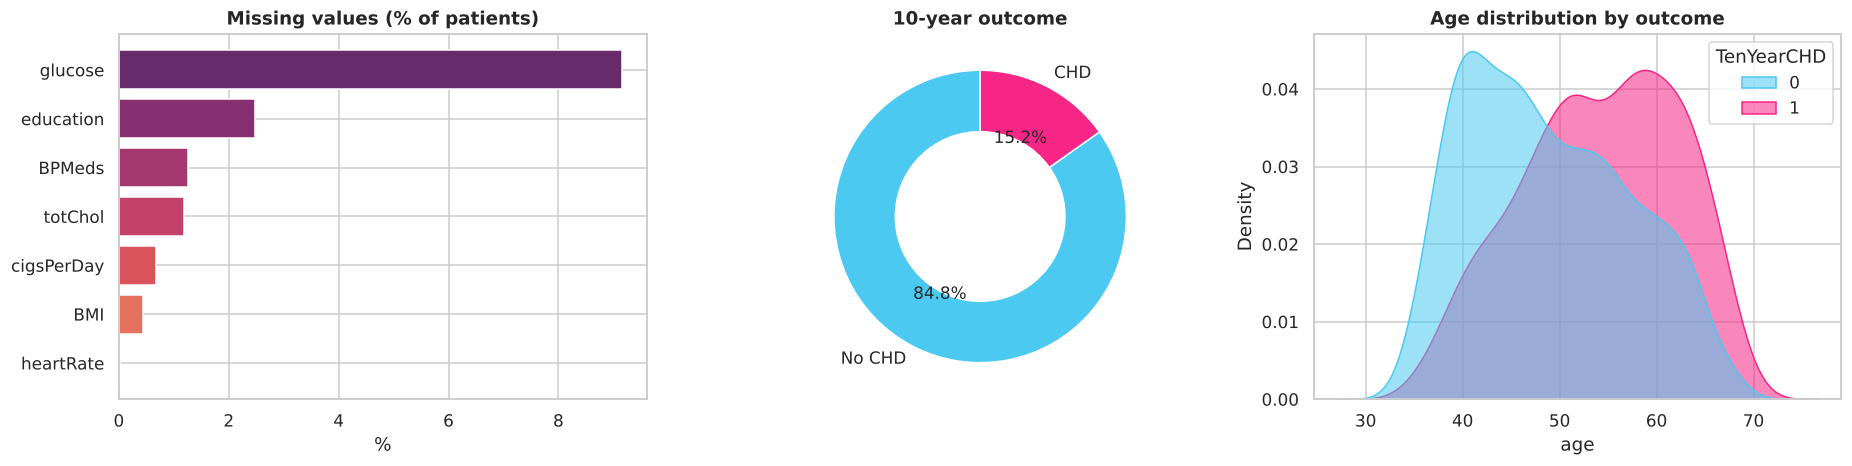

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
miss = (df.isna().mean() * 100); miss = miss[miss > 0].sort_values()
ax[0].barh(miss.index, miss.values, color=sns.color_palette("flare", len(miss)))
ax[0].set(title="Missing values (% of patients)", xlabel="%")

counts = df[TARGET].value_counts().sort_index()
ax[1].pie(counts, labels=["No CHD", "CHD"], autopct="%1.1f%%", colors=OUTCOME_COLORS, startangle=90,
          wedgeprops=dict(width=0.42, edgecolor="white"), textprops={"fontsize": 11})
ax[1].set_title("10-year outcome")

sns.kdeplot(data=df, x="age", hue=TARGET, fill=True, common_norm=False, palette=OUTCOME_COLORS, ax=ax[2], alpha=.55)
ax[2].set_title("Age distribution by outcome")
plt.tight_layout(); plt.show()

**How to read this: Missing values, outcome split and age by outcome**

Bars show the percentage of patients with no recorded value for each measurement. Glucose is usually the largest gap, which is why the pipeline adds a 'glucose missing' flag and fills the rest with the median instead of dropping rows.

Share of patients in the dataset who did or did not develop CHD within 10 years. It shows how imbalanced the problem is: far fewer people have the outcome than not, which is why accuracy alone is a poor yardstick.

The right-hand density plot compares the age distribution of patients with and without CHD. A CHD curve sitting further right shows that older patients are more likely to develop it.

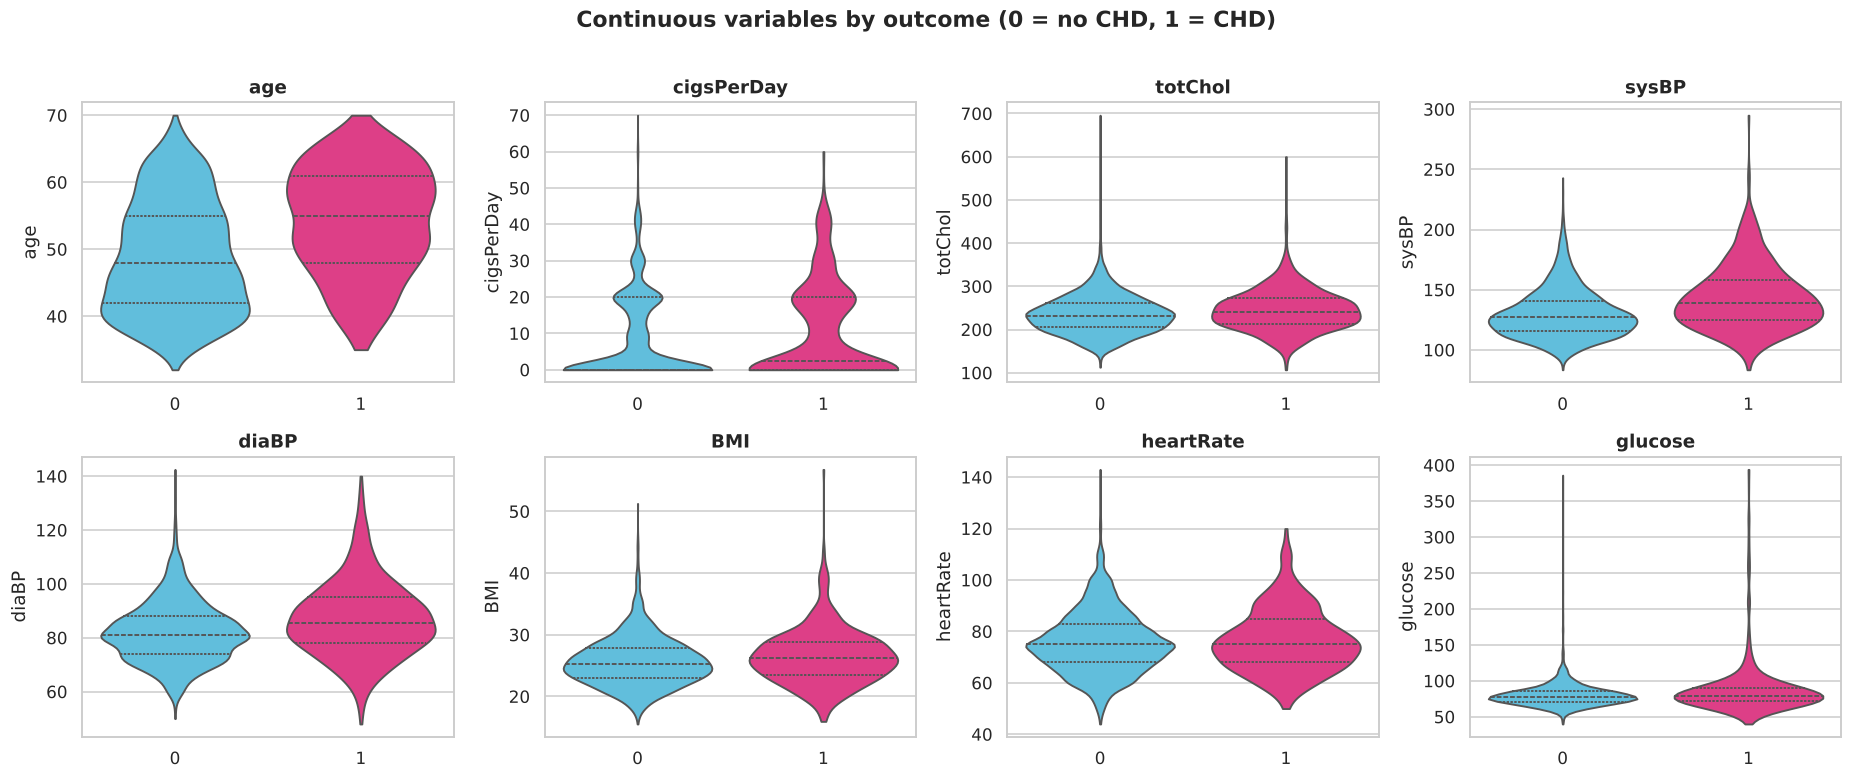

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for a, col in zip(axes.ravel(), CONTINUOUS):
    sns.violinplot(data=df, x=TARGET, y=col, hue=TARGET, palette=OUTCOME_COLORS, inner="quartile", legend=False, ax=a, cut=0)
    a.set_title(col); a.set_xlabel("")
plt.suptitle("Continuous variables by outcome (0 = no CHD, 1 = CHD)", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

**How to read this: Violin plots by outcome**

Each violin shows how a measurement is spread, separately for patients without CHD (0) and with CHD (1). Wider parts mean more patients at that value and the inner lines mark the quartiles. A CHD violin shifted upward for a variable, as is typical for age and blood pressure, signals that it helps separate the groups.

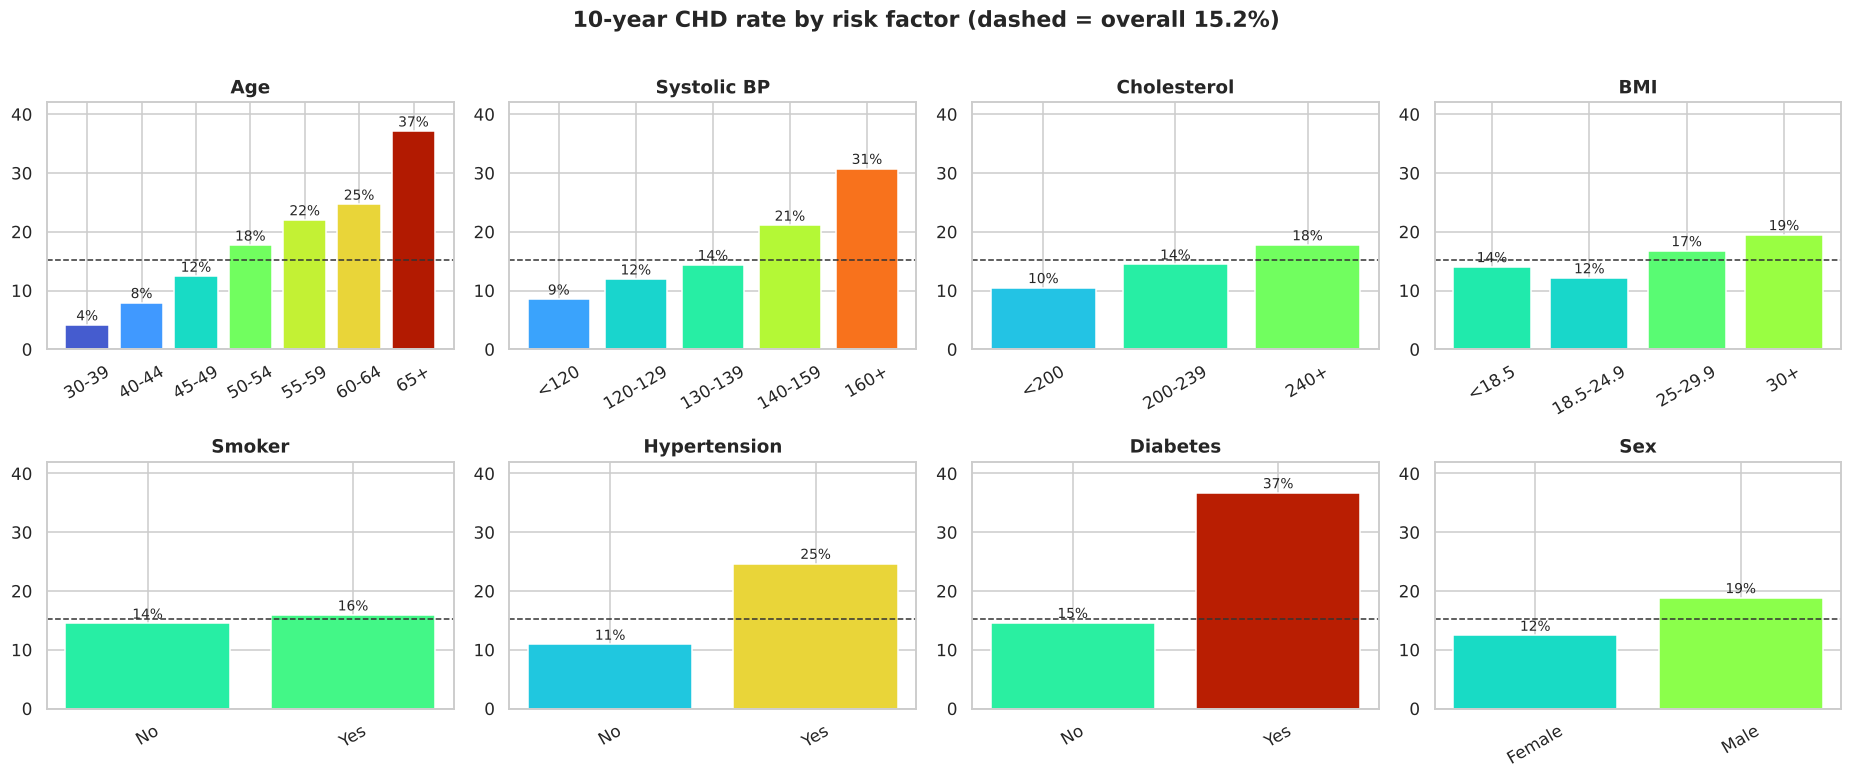

In [6]:
# CHD rate by risk factor, bars coloured by the rate itself
bands = {
    "Age": pd.cut(df.age, [30, 40, 45, 50, 55, 60, 65, 75], right=False, labels=["30-39", "40-44", "45-49", "50-54", "55-59", "60-64", "65+"]),
    "Systolic BP": pd.cut(df.sysBP, [0, 120, 130, 140, 160, 400], right=False, labels=["<120", "120-129", "130-139", "140-159", "160+"]),
    "Cholesterol": pd.cut(df.totChol, [0, 200, 240, 1000], right=False, labels=["<200", "200-239", "240+"]),
    "BMI": pd.cut(df.BMI, [0, 18.5, 25, 30, 100], right=False, labels=["<18.5", "18.5-24.9", "25-29.9", "30+"]),
    "Smoker": df.currentSmoker.map({0: "No", 1: "Yes"}), "Hypertension": df.prevalentHyp.map({0: "No", 1: "Yes"}),
    "Diabetes": df.diabetes.map({0: "No", 1: "Yes"}), "Sex": df.male.map({0: "Female", 1: "Male"}),
}
fig, axes = plt.subplots(2, 4, figsize=(17, 7)); avg = df[TARGET].mean() * 100
norm = plt.Normalize(0, 40)
for a, (name, s) in zip(axes.ravel(), bands.items()):
    r = df.groupby(s, observed=True)[TARGET].mean() * 100
    a.bar(r.index.astype(str), r.values, color=plt.cm.turbo(norm(r.values)), edgecolor="white")
    a.axhline(avg, color="#333", ls="--", lw=1); a.set_title(name); a.set_ylim(0, 42)
    for i, v in enumerate(r.values): a.text(i, v + .8, f"{v:.0f}%", ha="center", fontsize=9)
    a.tick_params(axis="x", rotation=30)
plt.suptitle(f"10-year CHD rate by risk factor (dashed = overall {avg:.1f}%)", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

**How to read this: CHD rate by risk factor**

Patients are grouped by the chosen factor and each bar is the share who developed CHD. The dashed line is the overall rate, so bars above it are higher-risk groups. Hover for the group size, because small groups give noisy rates. Bar colour also follows the rate, so the redder bars stand out at a glance.

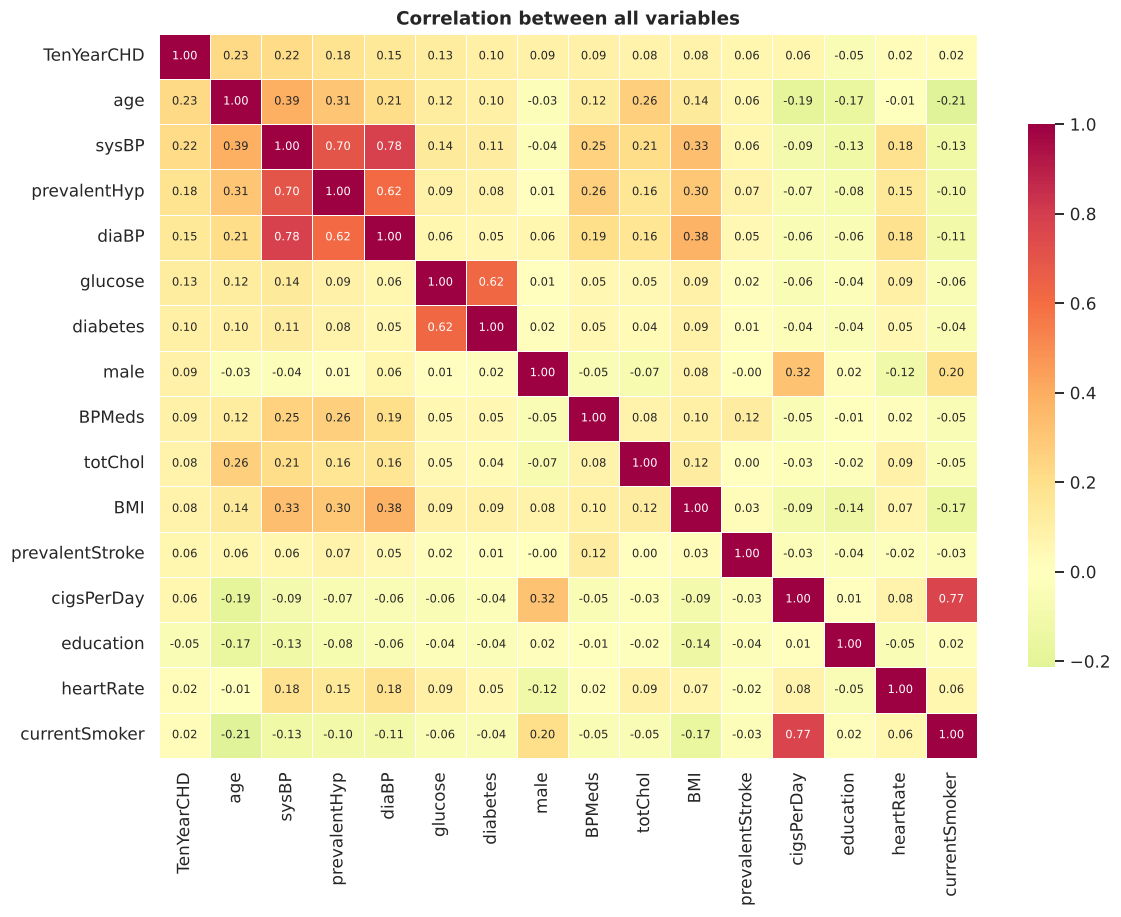

In [7]:
corr = df[FEATURES + [TARGET]].corr()
order = corr[TARGET].abs().sort_values(ascending=False).index
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr.loc[order, order], cmap="Spectral_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7.5},
            linewidths=.6, linecolor="white", cbar_kws={"shrink": .75})
plt.title("Correlation between all variables"); plt.tight_layout(); plt.show()

**How to read this: Correlation heatmap**

Each cell is the correlation (r) between two variables, from -1 (move in opposite directions) to +1 (move together); 0 means no linear link. Variables are sorted by their link with the 10-year CHD outcome. Strongly related pairs, like systolic and diastolic pressure, carry overlapping information.

## 4. Preprocessing

All statistics (medians, modes, scaling) are **learned from the training data only**. The preprocessor is an sklearn transformer, so cross-validation refits it inside every fold, which prevents leakage.

Rules: a non-smoker with no cigarette count gets 0; a smoker with none gets the smoker median; glucose gets a `glucose_missing` flag; other gaps get the median (numeric) or mode (categorical); continuous columns are standardised.

In [8]:
FEATURES_OUT = FEATURES + ["glucose_missing"]


def to_frame(X) -> pd.DataFrame:
    """Coerce a DataFrame, list of dicts or ndarray into a numeric frame with the FEATURES columns."""
    frame = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X, columns=FEATURES if isinstance(X, np.ndarray) else None)
    for col in FEATURES:
        if col not in frame.columns:
            frame[col] = np.nan
    return frame[FEATURES].apply(pd.to_numeric, errors="coerce").reset_index(drop=True)


class FraminghamPreprocessor(BaseEstimator, TransformerMixin):
    """Impute, add a glucose-missing flag, and standardise continuous columns."""

    def fit(self, X, y=None):
        X = to_frame(X)
        self.medians_ = {c: float(X[c].median()) for c in CONTINUOUS}
        self.modes_ = {c: float(X[c].mode().iloc[0]) for c in BINARY + ORDINAL}
        self.smoker_cigs_median_ = float(X.loc[X["currentSmoker"] == 1, "cigsPerDay"].median())
        self.scaler_ = StandardScaler().fit(self._impute(X)[CONTINUOUS])
        return self

    def _impute(self, X):
        X = X.copy()
        X["glucose_missing"] = X["glucose"].isna().astype(int)
        X.loc[(X["currentSmoker"] == 0) & X["cigsPerDay"].isna(), "cigsPerDay"] = 0.0
        X.loc[(X["currentSmoker"] == 1) & X["cigsPerDay"].isna(), "cigsPerDay"] = self.smoker_cigs_median_
        for col, val in {**self.medians_, **self.modes_}.items():
            X[col] = X[col].fillna(val)
        return X

    def transform(self, X):
        X = self._impute(to_frame(X))
        X[CONTINUOUS] = self.scaler_.transform(X[CONTINUOUS])
        return X[FEATURES_OUT].to_numpy(dtype=np.float32)

    def reference_profile(self):
        """A 'typical patient' (train medians / modes) used for what-if explanations."""
        ref = {**self.medians_, **self.modes_}
        ref["cigsPerDay"] = 0.0 if ref["currentSmoker"] == 0 else self.smoker_cigs_median_
        return {c: ref[c] for c in FEATURES}


# Stratified split BEFORE anything is learned
train_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df[TARGET], random_state=SEED)
X_tr, y_tr = train_df[FEATURES], train_df[TARGET].to_numpy()
X_te, y_te = test_df[FEATURES], test_df[TARGET].to_numpy()
print(f"train {X_tr.shape}  CHD {y_tr.mean():.3f} | test {X_te.shape}  CHD {y_te.mean():.3f}")

# Demonstration: before and after on a few rows that have gaps
prep_demo = FraminghamPreprocessor().fit(X_tr)
rows = X_tr[X_tr.isna().any(axis=1)].head(4)
display(rows)
display(pd.DataFrame(prep_demo.transform(rows), columns=FEATURES_OUT).round(2))

train (3392, 15)  CHD 0.152 | test (848, 15)  CHD 0.152


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
433,0,45,2.0,0,0.0,0.0,0,1,0,226.0,180.0,99.0,45.79,110.0,NaN
2431,0,47,4.0,1,20.0,0.0,0,0,0,261.0,120.0,77.5,23.26,85.0,NaN
2060,1,38,NaN,0,0.0,0.0,0,0,0,221.0,119.0,84.0,26.89,66.0,82.0
4162,0,47,3.0,1,9.0,NaN,0,0,0,221.0,127.5,75.0,23.78,69.0,73.0


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,glucose_missing
0,0.0,-0.54,2.0,0.0,-0.76,0.0,0.0,1.0,0.0,-0.24,2.16,1.36,4.85,2.84,-0.16,1.0
1,0.0,-0.31,4.0,1.0,0.91,0.0,0.0,0.0,0.0,0.55,-0.56,-0.45,-0.62,0.76,-0.16,1.0
2,1.0,-1.36,1.0,0.0,-0.76,0.0,0.0,0.0,0.0,-0.36,-0.61,0.09,0.26,-0.82,0.02,0.0
3,0.0,-0.31,3.0,1.0,-0.01,0.0,0.0,0.0,0.0,-0.36,-0.22,-0.66,-0.50,-0.57,-0.37,0.0


## 5. Models

Every model is a `Pipeline(preprocessor → classifier)`. The ANN is a small PyTorch network (Linear → BatchNorm → ReLU → Dropout blocks) wrapped in an sklearn-style class so it can be cross-validated like the others. No class weighting is used, so predicted probabilities stay interpretable; the decision threshold is tuned later instead.

In [9]:
class _Net(nn.Module):
    def __init__(self, n_in, hidden, dropout):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.body = nn.Sequential(*layers)

    def forward(self, x):
        return self.body(x).squeeze(-1)


class TorchMLPClassifier(ClassifierMixin, BaseEstimator):
    """MLP trained with AdamW and early stopping on a held-out slice of the training data."""

    def __init__(self, hidden=(64, 32), dropout=0.3, lr=1e-3, weight_decay=1e-3, batch_size=128,
                 max_epochs=200, patience=15, val_fraction=0.15, seed=42):
        self.hidden, self.dropout, self.lr, self.weight_decay = hidden, dropout, lr, weight_decay
        self.batch_size, self.max_epochs, self.patience = batch_size, max_epochs, patience
        self.val_fraction, self.seed = val_fraction, seed

    def fit(self, X, y):
        import copy
        X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)
        self.classes_ = np.array([0, 1])
        torch.manual_seed(self.seed); rng = np.random.RandomState(self.seed)
        Xt, Xv, yt, yv = train_test_split(X, y, test_size=self.val_fraction, stratify=y, random_state=self.seed)
        Xt_t, yt_t, Xv_t, yv_t = map(torch.from_numpy, (Xt, yt, Xv, yv))
        net = _Net(X.shape[1], tuple(self.hidden), self.dropout)
        opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.BCEWithLogitsLoss()
        best, best_state, wait = np.inf, None, 0
        self.history_ = {"train_loss": [], "val_loss": [], "val_auc": []}
        for _ in range(self.max_epochs):
            net.train(); order = rng.permutation(len(Xt)); running = 0.0
            for i in range(0, len(order), self.batch_size):
                idx = order[i:i + self.batch_size]
                if len(idx) < 2:
                    continue
                opt.zero_grad(); loss = loss_fn(net(Xt_t[idx]), yt_t[idx]); loss.backward(); opt.step()
                running += loss.item() * len(idx)
            net.eval()
            with torch.no_grad():
                logits = net(Xv_t); vloss = loss_fn(logits, yv_t).item()
            self.history_["train_loss"].append(running / len(Xt))
            self.history_["val_loss"].append(vloss)
            self.history_["val_auc"].append(float(roc_auc_score(yv, logits.numpy())))
            if vloss < best - 1e-4:
                best, best_state, wait = vloss, copy.deepcopy(net.state_dict()), 0
            else:
                wait += 1
                if wait >= self.patience:
                    break
        net.load_state_dict(best_state); net.eval()
        self.net_, self.n_in_ = net, X.shape[1]
        self.best_epoch_ = int(np.argmin(self.history_["val_loss"])) + 1
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            p = torch.sigmoid(self.net_(torch.from_numpy(np.asarray(X, dtype=np.float32)))).numpy().astype(np.float64)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def build_models(seed=SEED):
    pipe = lambda clf: Pipeline([("prep", FraminghamPreprocessor()), ("clf", clf)])
    return {
        "Logistic Regression": pipe(LogisticRegression(C=0.5, max_iter=2000)),
        "Random Forest": pipe(RandomForestClassifier(n_estimators=500, min_samples_leaf=10, max_features="sqrt", n_jobs=2, random_state=seed)),
        "XGBoost": pipe(XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
                                      min_child_weight=5, reg_lambda=5.0, eval_metric="logloss", n_jobs=2, random_state=seed)),
        "ANN (MLP)": pipe(TorchMLPClassifier(hidden=(64, 32), dropout=0.3, lr=1e-3, weight_decay=1e-3, seed=seed)),
    }

print(list(build_models()))

['Logistic Regression', 'Random Forest', 'XGBoost', 'ANN (MLP)']


### Experimental setup and hyperparameters

All models share one stratified 80/20 split (seed 42) and 5-fold stratified cross-validation on the training part. Each is a pipeline of the same preprocessor and one classifier.

| Model | Settings |
|---|---|
| Logistic Regression | C = 0.5, L2 penalty, max_iter = 2000 |
| Random Forest | 500 trees, min_samples_leaf = 10, max_features = sqrt |
| XGBoost | 300 trees, max_depth = 3, learning_rate = 0.03, subsample = 0.8, colsample_bytree = 0.8, min_child_weight = 5, reg_lambda = 5 |
| ANN (MLP) | hidden layers 64 and 32 with BatchNorm, ReLU and dropout 0.3; AdamW, lr = 1e-3, weight decay = 1e-3; batch 128; early stopping (patience 15) on a 15% validation slice |

These are modest, regularised defaults. Section 6c tests whether a grid search improves on them.

## 6. Validation and testing

1. 5-fold stratified cross-validation on the training split gives out-of-fold probabilities for every model.
2. The decision threshold maximises Youden's J (sensitivity + specificity − 1) on those out-of-fold predictions.
3. Each model is refit on all training data and scored **once** on the held-out test set.
4. The model to deploy is chosen by **cross-validated AUC only**, so the test set stays an honest final check.

In [10]:
def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])


def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"roc_auc": round(float(roc_auc_score(y, p)), 4), "pr_auc": round(float(average_precision_score(y, p)), 4),
            "brier": round(float(brier_score_loss(y, p)), 4), "threshold": round(float(thr), 4),
            "accuracy": round(float((tp + tn) / len(y)), 4), "balanced_accuracy": round(float(balanced_accuracy_score(y, pred)), 4),
            "recall_sensitivity": round(float(recall_score(y, pred)), 4), "specificity": round(float(tn / (tn + fp)), 4),
            "precision": round(float(precision_score(y, pred, zero_division=0)), 4), "f1": round(float(f1_score(y, pred)), 4),
            "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}}


cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
models, results, test_proba, oof_proba = build_models(), {}, {}, {}
for name, pipe in models.items():
    oof = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    thr = youden_threshold(y_tr, oof)
    pipe.fit(X_tr, y_tr)
    p_test = pipe.predict_proba(X_te)[:, 1]
    results[name] = {"cv": metrics_at(y_tr, oof, thr), "test": metrics_at(y_te, p_test, thr)}
    test_proba[name], oof_proba[name] = p_test, oof
    print(f"{name:20s} CV AUC {results[name]['cv']['roc_auc']:.3f} | test AUC {results[name]['test']['roc_auc']:.3f} "
          f"| sens {results[name]['test']['recall_sensitivity']:.2f} spec {results[name]['test']['specificity']:.2f}")

best = max(results, key=lambda n: results[n]["cv"]["roc_auc"])
print("\nBest model by cross-validated AUC:", best)

Logistic Regression  CV AUC 0.730 | test AUC 0.698 | sens 0.60 spec 0.69


Random Forest        CV AUC 0.720 | test AUC 0.668 | sens 0.64 spec 0.62


XGBoost              CV AUC 0.716 | test AUC 0.675 | sens 0.53 spec 0.69


ANN (MLP)            CV AUC 0.727 | test AUC 0.686 | sens 0.56 spec 0.67

Best model by cross-validated AUC: Logistic Regression


In [11]:
summary = pd.DataFrame([{"Model": n, "CV AUC": r["cv"]["roc_auc"], "Test AUC": r["test"]["roc_auc"], "Test PR-AUC": r["test"]["pr_auc"],
                         "Sensitivity": r["test"]["recall_sensitivity"], "Specificity": r["test"]["specificity"],
                         "Precision": r["test"]["precision"], "F1": r["test"]["f1"], "Threshold": r["cv"]["threshold"]}
                        for n, r in results.items()]).set_index("Model")
display(summary.style.background_gradient(cmap="RdYlGn", axis=0).format("{:.3f}"))
print(f"Test set: {len(y_te)} patients, {int(y_te.sum())} with CHD. Expect about ±0.03 of noise in test AUC.")

,CV AUC,Test AUC,Test PR-AUC,Sensitivity,Specificity,Precision,F1,Threshold
Model,,,,,,,,
Logistic Regression,0.730,0.698,0.298,0.597,0.687,0.255,0.357,0.155
Random Forest,0.720,0.668,0.272,0.636,0.616,0.229,0.337,0.143
XGBoost,0.716,0.675,0.291,0.535,0.687,0.235,0.326,0.160
ANN (MLP),0.727,0.686,0.281,0.558,0.674,0.235,0.331,0.177


Test set: 848 patients, 129 with CHD. Expect about ±0.03 of noise in test AUC.


## 6b. Final results: comparing the models

Which model wins, on which metric, and why the served model was chosen. Values come straight from `results` above.

In [ ]:
def final_verdict(R, serving):
    """Plain-language comparison built only from the metrics in metrics.json (so it always matches the data)."""
    names = list(R)
    top = lambda key, part: max(names, key=lambda n: R[n][part][key])
    cv_best, auc_best = top("roc_auc", "cv"), top("roc_auc", "test")
    sens_best, spec_best = top("recall_sensitivity", "test"), top("specificity", "test")
    f1_best, brier_best = top("f1", "test"), min(names, key=lambda n: R[n]["test"]["brier"])
    spread = max(R[n]["cv"]["roc_auc"] for n in names) - min(R[n]["cv"]["roc_auc"] for n in names)
    rows = [("Best cross-validated AUC (model selection)", cv_best, R[cv_best]["cv"]["roc_auc"]),
            ("Best test AUC", auc_best, R[auc_best]["test"]["roc_auc"]),
            ("Highest sensitivity (catches most CHD)", sens_best, R[sens_best]["test"]["recall_sensitivity"]),
            ("Highest specificity (fewest false alarms)", spec_best, R[spec_best]["test"]["specificity"]),
            ("Best F1", f1_best, R[f1_best]["test"]["f1"]),
            ("Lowest Brier score (best probabilities)", brier_best, R[brier_best]["test"]["brier"])]
    text = (f"**{serving}** is served: it has the best cross-validated AUC ({R[serving]['cv']['roc_auc']:.3f}) and was picked before the test set was opened. "
            f"The {len(names)} models sit within {spread:.3f} AUC of each other in cross-validation, so the gaps are small relative to the test set's noise of about ±0.03. "
            f"{'No model wins every metric, and a simpler, more explainable model is preferred when accuracy is this close.' if len({r[1] for r in rows}) > 1 else 'It also leads on every metric above.'}")
    return rows, text


rows, verdict = final_verdict(results, best)
print(verdict.replace("**", ""), "\n")
display(pd.DataFrame(rows, columns=["Criterion", "Winner", "Value"]).set_index("Criterion").style.format({"Value": "{:.3f}"}))

final = pd.DataFrame([{"Model": n, "CV AUC": r["cv"]["roc_auc"], "Test AUC": r["test"]["roc_auc"], "Sensitivity": r["test"]["recall_sensitivity"],
                       "Specificity": r["test"]["specificity"], "Brier": r["test"]["brier"]} for n, r in results.items()])
final.insert(1, "Rank (CV AUC)", final["CV AUC"].rank(ascending=False).astype(int))
display(final.sort_values("Rank (CV AUC)").set_index("Model").style.background_gradient(cmap="RdYlGn", subset=["CV AUC", "Test AUC", "Sensitivity", "Specificity"]).format({"Brier": "{:.3f}", "CV AUC": "{:.3f}", "Test AUC": "{:.3f}", "Sensitivity": "{:.3f}", "Specificity": "{:.3f}"}))


## 6c. Hyperparameter tuning and feature engineering (experiments)

These two experiments use **training data only** with the same 5-fold split, and they do not overwrite the models above, so the saved artifacts and the dashboard stay consistent. Run them to report whether tuning or the extra features help. Pulse pressure (sysBP - diaBP) and mean arterial pressure are standard blood-pressure features.

In [ ]:
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer

# ---- A. Hyperparameter tuning (cross-validated grid search on the training split) ----
grids = {
    "Logistic Regression": (Pipeline([("prep", FraminghamPreprocessor()), ("clf", LogisticRegression(max_iter=2000))]),
                            {"clf__C": [0.01, 0.1, 0.5, 1, 5]}),
    "Random Forest": (Pipeline([("prep", FraminghamPreprocessor()), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))]),
                      {"clf__n_estimators": [200, 400], "clf__max_depth": [4, 6, 8], "clf__min_samples_leaf": [5, 10, 20]}),
}
tuned = []
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=1).fit(X_tr, y_tr)
    tuned.append({"Model": name, "Default CV AUC": results[name]["cv"]["roc_auc"], "Tuned CV AUC": round(gs.best_score_, 4), "Best parameters": gs.best_params_})
display(pd.DataFrame(tuned).set_index("Model"))

In [ ]:
# ---- B. Feature engineering: do pulse pressure and MAP add signal? ----
def add_features(X):
    X = to_frame(X)
    X["pulse_pressure"] = X["sysBP"] - X["diaBP"]
    X["map"] = X["diaBP"] + (X["sysBP"] - X["diaBP"]) / 3
    return X

def simple_lr():
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", LogisticRegression(C=0.5, max_iter=2000))])

base_auc = cross_val_score(simple_lr(), to_frame(X_tr), y_tr, cv=cv, scoring="roc_auc")
eng_auc = cross_val_score(simple_lr(), add_features(X_tr), y_tr, cv=cv, scoring="roc_auc")
display(pd.DataFrame({"Feature set": ["Original 15 features", "+ pulse pressure and MAP"],
                      "CV AUC (mean)": [base_auc.mean(), eng_auc.mean()], "CV AUC (std)": [base_auc.std(), eng_auc.std()]}).set_index("Feature set").round(4))
print("Keep the engineered features only if the gain is larger than the fold-to-fold spread.")

# Save for the dashboard
fe_tbl = pd.DataFrame({"Feature set": ["Original 15 features", "+ pulse pressure and MAP"],
                       "CV AUC (mean)": [base_auc.mean(), eng_auc.mean()], "CV AUC (std)": [base_auc.std(), eng_auc.std()]}).round(4)
(ART / "experiments.json").write_text(json.dumps({"tuning": [{**t, "Best parameters": {k.replace("clf__", ""): v for k, v in t["Best parameters"].items()}} for t in tuned],
                                                   "feature_engineering": fe_tbl.to_dict(orient="records")}, indent=1, default=float))
print("saved artifacts/experiments.json")

## 7. Evaluation plots

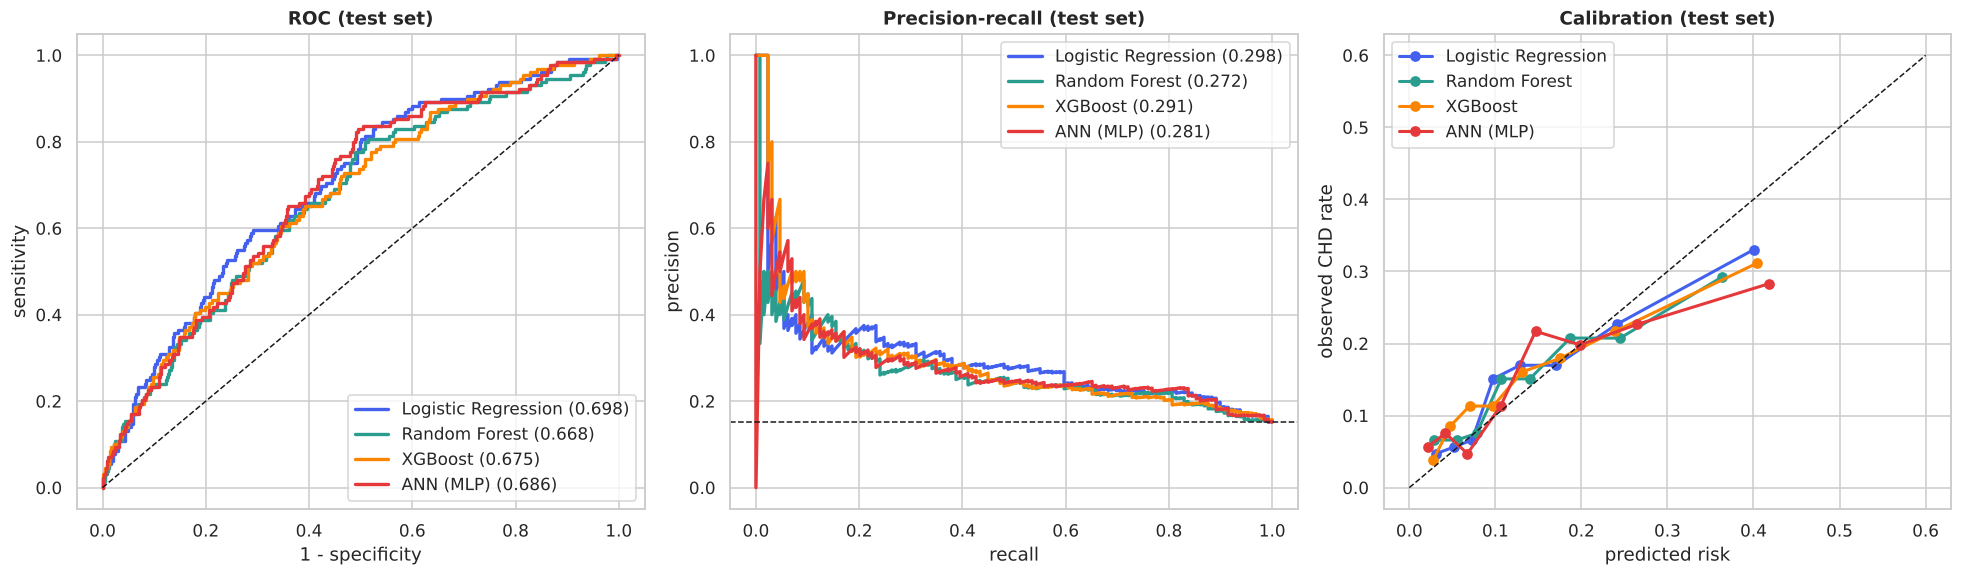

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.4))
for n, p in test_proba.items():
    c = MODEL_COLORS[n]
    f, t, _ = roc_curve(y_te, p); ax[0].plot(f, t, color=c, lw=2.2, label=f"{n} ({results[n]['test']['roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p); ax[1].plot(rc, pr, color=c, lw=2.2, label=f"{n} ({results[n]['test']['pr_auc']:.3f})")
    fr, mp = calibration_curve(y_te, p, n_bins=8, strategy="quantile"); ax[2].plot(mp, fr, "o-", color=c, lw=2, label=n)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(title="ROC (test set)", xlabel="1 - specificity", ylabel="sensitivity")
ax[1].axhline(y_te.mean(), color="k", ls="--", lw=1); ax[1].set(title="Precision-recall (test set)", xlabel="recall", ylabel="precision")
ax[2].plot([0, .6], [0, .6], "k--", lw=1); ax[2].set(title="Calibration (test set)", xlabel="predicted risk", ylabel="observed CHD rate")
for a in ax: a.legend(frameon=True)
plt.tight_layout(); plt.show()

**How to read this: ROC, precision-recall and calibration**

ROC: curves closer to the top-left are better and the dashed diagonal is a coin flip. Precision-recall: higher is better, which matters for the rarer CHD class. Calibration: points near the dashed diagonal mean predicted risk matches the observed rate, so '20%' really means about 20 in 100.

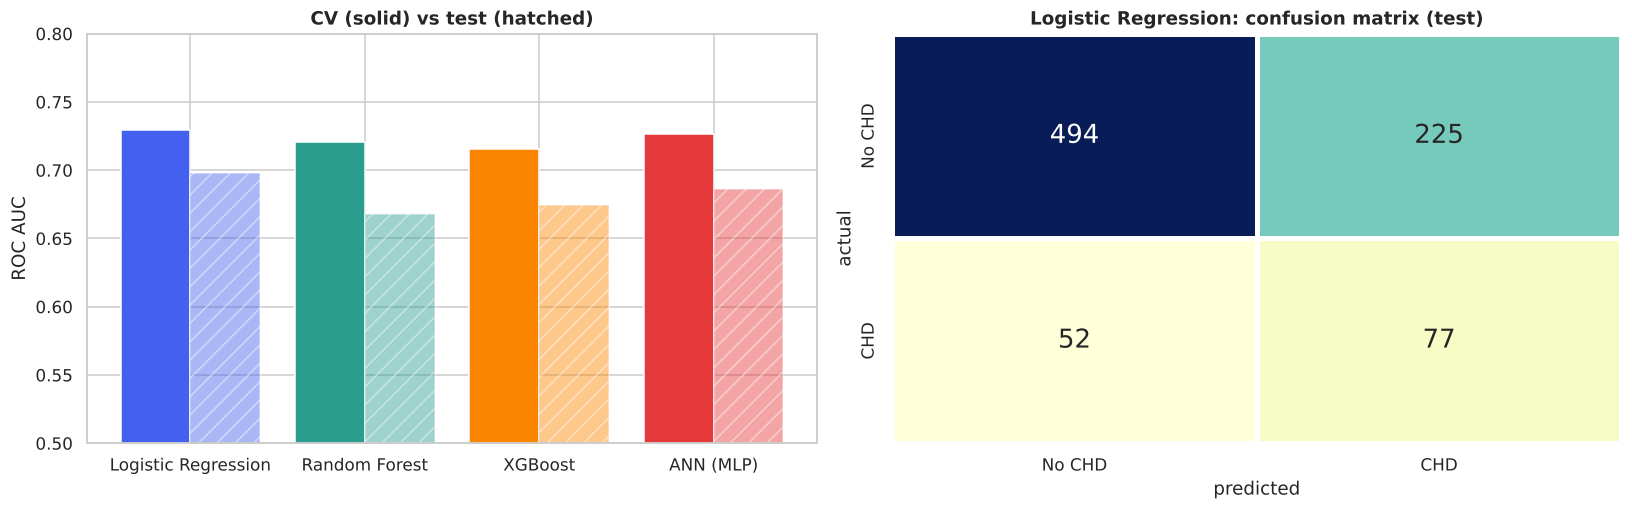

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
names = list(results); x = np.arange(len(names))
ax[0].bar(x - .2, [results[n]["cv"]["roc_auc"] for n in names], .4, color=[MODEL_COLORS[n] for n in names], label="5-fold CV")
ax[0].bar(x + .2, [results[n]["test"]["roc_auc"] for n in names], .4, color=[MODEL_COLORS[n] for n in names], alpha=.45, hatch="//", label="Held-out test")
ax[0].set(xticks=x, xticklabels=names, ylim=(.5, .8), ylabel="ROC AUC", title="CV (solid) vs test (hatched)")
cm = results[best]["test"]["confusion"]
sns.heatmap([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]], annot=True, fmt="d", cmap="YlGnBu", cbar=False, annot_kws={"size": 17},
            xticklabels=["No CHD", "CHD"], yticklabels=["No CHD", "CHD"], ax=ax[1], linewidths=3, linecolor="white")
ax[1].set(title=f"{best}: confusion matrix (test)", xlabel="predicted", ylabel="actual")
plt.tight_layout(); plt.show()

**How to read this: AUC comparison and confusion matrix**

**Left (AUC bars).** Solid bars are the cross-validated AUC used to choose the model and hatched bars are the held-out test AUC. Similar heights mean the model generalises. Gaps of about 0.03 are expected from test-set noise and are not proof that one model is better.

**Right (confusion matrix).** Rows are the true outcome and columns are the model's prediction on the test set. The top-left and bottom-right cells are correct calls. Top-right is false alarms and bottom-left is missed CHD cases. Sensitivity and specificity are computed from these four counts.

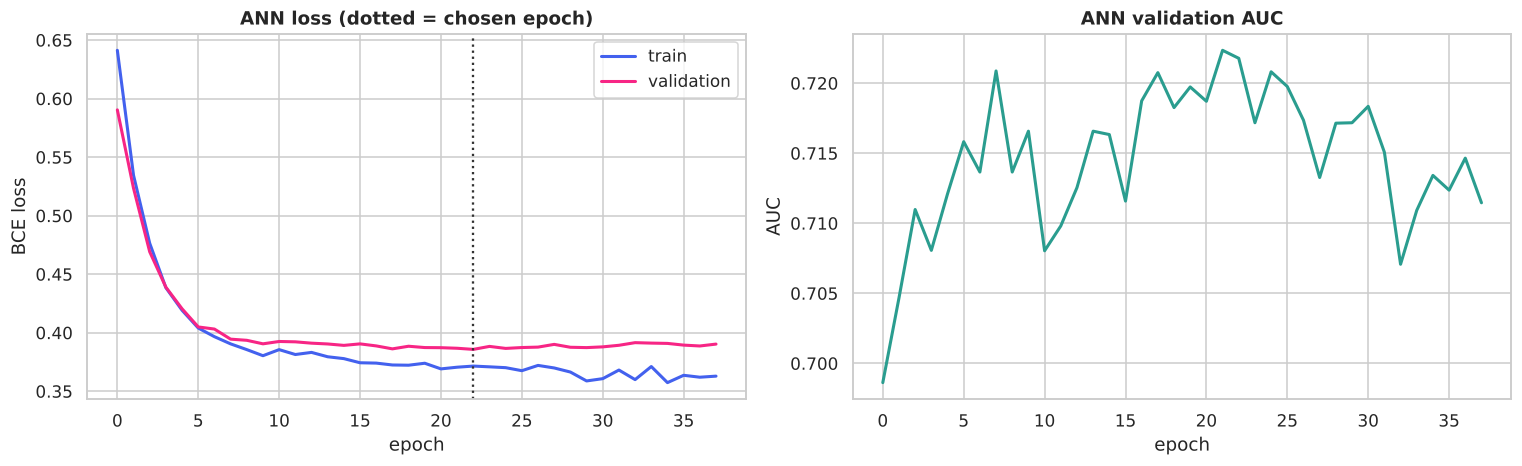

In [14]:
hist = models["ANN (MLP)"].named_steps["clf"].history_
bestep = models["ANN (MLP)"].named_steps["clf"].best_epoch_
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].plot(hist["train_loss"], color="#4361ee", lw=2, label="train"); ax[0].plot(hist["val_loss"], color="#f72585", lw=2, label="validation")
ax[0].axvline(bestep - 1, color="#333", ls=":"); ax[0].set(title="ANN loss (dotted = chosen epoch)", xlabel="epoch", ylabel="BCE loss"); ax[0].legend()
ax[1].plot(hist["val_auc"], color="#2a9d8f", lw=2); ax[1].set(title="ANN validation AUC", xlabel="epoch", ylabel="AUC")
plt.tight_layout(); plt.show()

**How to read this: ANN training curves**

Left: training loss (blue) versus validation loss (pink) per epoch, with the dotted line marking the epoch kept by early stopping. If validation loss rises while training loss keeps falling, the network is overfitting. Right: validation AUC over the same epochs.

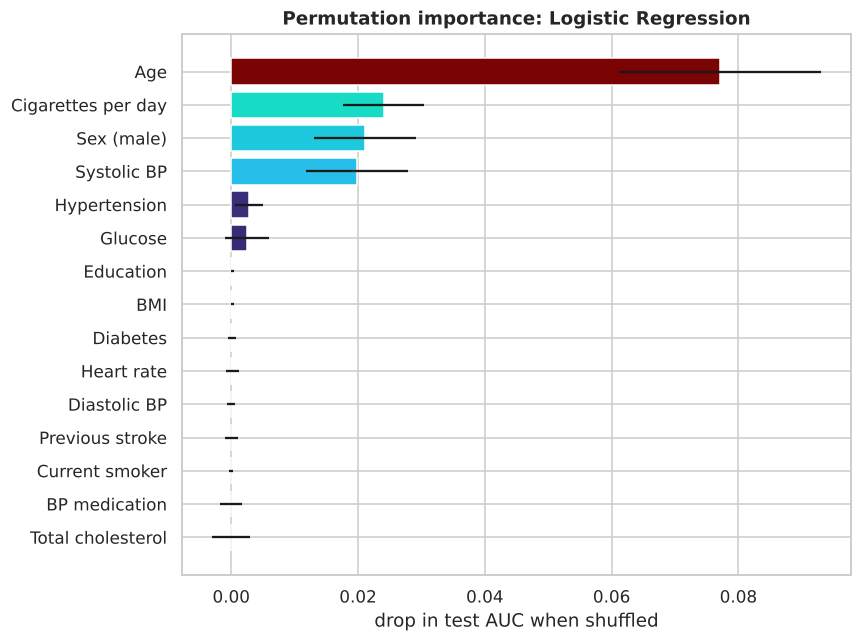

In [15]:
# Which features matter? Permutation importance of the deployed model on the test set
best_pipe = models[best]
pi = permutation_importance(best_pipe, X_te, y_te, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=1)
LABELS = {"male": "Sex (male)", "age": "Age", "education": "Education", "currentSmoker": "Current smoker", "cigsPerDay": "Cigarettes per day",
          "BPMeds": "BP medication", "prevalentStroke": "Previous stroke", "prevalentHyp": "Hypertension", "diabetes": "Diabetes",
          "totChol": "Total cholesterol", "sysBP": "Systolic BP", "diaBP": "Diastolic BP", "BMI": "BMI", "heartRate": "Heart rate", "glucose": "Glucose"}
importance = sorted([{"feature": f, "label": LABELS[f], "importance": round(float(m), 5), "std": round(float(s), 5)}
                     for f, m, s in zip(FEATURES, pi.importances_mean, pi.importances_std)], key=lambda r: -r["importance"])
imp = pd.DataFrame(importance).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(imp.label, imp.importance.clip(lower=0), xerr=imp["std"], color=plt.cm.turbo(plt.Normalize(0, imp.importance.max())(imp.importance.clip(lower=0))))
plt.title(f"Permutation importance: {best}"); plt.xlabel("drop in test AUC when shuffled"); plt.tight_layout(); plt.show()

**How to read this: Permutation importance**

Permutation importance: each feature is shuffled in turn and the bar shows how much the test AUC drops. A longer bar means the model relies on that feature more. Error bars show variation across repeats, and a bar near zero means the feature adds little.

## 8. Explaining one patient

For a single patient we swap each factor, one at a time, to the *typical* value (training median/mode) and measure how much the predicted risk changes. Smoking status and cigarettes per day are swapped together so the explanation never describes an impossible patient. Positive = raises risk compared with a typical patient.

Predicted 10-year CHD risk: 80.6%  (cohort average 15.2%)


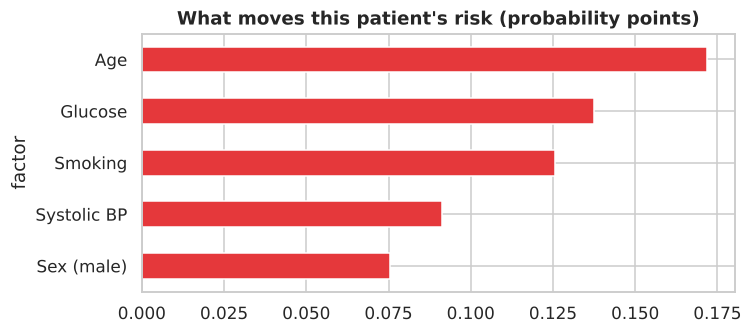

In [16]:
GROUPS = {"Smoking": ["currentSmoker", "cigsPerDay"]}


def local_factors(model, frame, reference, top_k=5):
    """model needs predict_proba(DataFrame). Returns, per row, the top factors by absolute risk change."""
    grouped = {f for fs in GROUPS.values() for f in fs}
    factors = {LABELS[f]: [f] for f in FEATURES if f not in grouped}
    factors.update(GROUPS)
    base = model.predict_proba(frame)[:, 1]
    names, deltas = list(factors), np.zeros((len(frame), len(factors)))
    for j, label in enumerate(names):
        swapped = frame.copy()
        for f in factors[label]:
            swapped[f] = reference[f]
        deltas[:, j] = base - model.predict_proba(swapped)[:, 1]
    out = []
    for i in range(len(frame)):
        rows = []
        for j in np.argsort(-np.abs(deltas[i]))[:top_k]:
            if abs(deltas[i, j]) > 1e-4:
                rows.append({"factor": names[j], "risk_change": round(float(deltas[i, j]), 4),
                             "direction": "increases risk" if deltas[i, j] > 0 else "lowers risk"})
        out.append(rows)
    return out


reference = best_pipe.named_steps["prep"].reference_profile()
patient = pd.DataFrame([{"male": 1, "age": 62, "currentSmoker": 1, "cigsPerDay": 30, "prevalentStroke": 0, "prevalentHyp": 1,
                         "diabetes": 1, "sysBP": 165, "diaBP": 98, "totChol": 280, "BMI": 31, "glucose": 180, "BPMeds": 1,
                         "heartRate": 82, "education": 1}])
p = best_pipe.predict_proba(patient)[0, 1]
print(f"Predicted 10-year CHD risk: {p:.1%}  (cohort average {y_tr.mean():.1%})")
fx = pd.DataFrame(local_factors(best_pipe, patient, reference)[0]).set_index("factor")
fx["risk_change"].iloc[::-1].plot.barh(color=["#e5383b" if v > 0 else "#2a9d8f" for v in fx["risk_change"].iloc[::-1]], figsize=(7, 3.2),
                                      title="What moves this patient's risk (probability points)")
plt.tight_layout(); plt.show()

**How to read this: What moves this patient's risk**

Each bar shows how much one factor changes your risk compared with a typical patient, in percentage points. Red bars push risk up, green bars pull it down, and the longest bars matter most. It is found by swapping one factor at a time to the typical value and re-scoring, so it describes this model, not cause and effect.

## 9. Save portable artifacts

Custom classes pickled inside a notebook cannot be loaded by another program. So the models are saved in **portable form**: preprocessing statistics as JSON, the scikit-learn / XGBoost estimators as plain objects, and the ANN as a weights file. The dashboard rebuilds predictions from these, and the next cell proves the round trip matches exactly.

In [17]:
slug = lambda n: n.lower().replace(" ", "_").replace("(", "").replace(")", "")
prep = best_pipe.named_steps["prep"]

# 1) preprocessing statistics
prm = {"features": FEATURES, "features_out": FEATURES_OUT, "continuous": CONTINUOUS,
       "medians": prep.medians_, "modes": prep.modes_, "smoker_cigs_median": prep.smoker_cigs_median_,
       "scaler_mean": prep.scaler_.mean_.tolist(), "scaler_scale": prep.scaler_.scale_.tolist()}
(ART / "preprocessing.json").write_text(json.dumps(prm, indent=2))

# 2) models
model_files = {}
for n, pipe in models.items():
    clf = pipe.named_steps["clf"]
    if n == "ANN (MLP)":
        f = f"models/{slug(n)}.pt"
        torch.save({"state_dict": clf.net_.state_dict(), "n_in": clf.n_in_, "hidden": list(clf.hidden), "dropout": clf.dropout}, ART / f)
    elif n == "XGBoost":
        f = f"models/{slug(n)}.json"          # native format: loads across xgboost versions
        clf.save_model(ART / f)
    else:
        f = f"models/{slug(n)}.joblib"
        joblib.dump(clf, ART / f)
    model_files[n] = f

# 3) evaluation outputs the dashboard plots
(ART / "metrics.json").write_text(json.dumps({"best_model": best, "results": results}, indent=2))
pd.DataFrame({"y": y_te, **{slug(n): p for n, p in test_proba.items()}}).round(5).to_csv(ART / "test_predictions.csv", index=False)
ann = models["ANN (MLP)"].named_steps["clf"]
(ART / "ann_history.json").write_text(json.dumps({**ann.history_, "best_epoch": ann.best_epoch_}))
(ART / "feature_importance.json").write_text(json.dumps(importance, indent=2))
(ART / "model_card.json").write_text(json.dumps({
    "best_model": best, "thresholds": {n: r["cv"]["threshold"] for n, r in results.items()},
    "base_rate": round(float(y_tr.mean()), 4), "reference_profile": prep.reference_profile(), "risk_bands": RISK_BANDS,
    "model_files": model_files, "model_colors": MODEL_COLORS, "labels": LABELS,
    "n_train": int(len(train_df)), "n_test": int(len(test_df)), "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "selection_rule": "highest 5-fold CV ROC AUC on the training split; test set not used for selection",
    "threshold_rule": "Youden J on out-of-fold training predictions",
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "torch": torch.__version__},
    "disclaimer": DISCLAIMER}, indent=2))
print("saved:", *sorted(str(p.relative_to(ROOT)) for p in ART.rglob("*") if p.is_file()), sep="\n  ")

saved:
  artifacts/ann_history.json
  artifacts/feature_importance.json
  artifacts/metrics.json
  artifacts/model_card.json
  artifacts/models/ann_mlp.pt
  artifacts/models/logistic_regression.joblib
  artifacts/models/random_forest.joblib
  artifacts/models/xgboost.json
  artifacts/preprocessing.json
  artifacts/test_predictions.csv


In [18]:
# Portable inference: exactly the code the dashboard uses. It needs no custom classes.
def prep_transform(X, prm):
    X = to_frame(X)
    X["glucose_missing"] = X["glucose"].isna().astype(int)
    X.loc[(X["currentSmoker"] == 0) & X["cigsPerDay"].isna(), "cigsPerDay"] = 0.0
    X.loc[(X["currentSmoker"] == 1) & X["cigsPerDay"].isna(), "cigsPerDay"] = prm["smoker_cigs_median"]
    for col, val in {**prm["medians"], **prm["modes"]}.items():
        X[col] = X[col].fillna(val)
    cont = prm["continuous"]
    X[cont] = (X[cont] - np.array(prm["scaler_mean"])) / np.array(prm["scaler_scale"])
    return X[prm["features_out"]].to_numpy(np.float32)


class PortableModel:
    def __init__(self, name, art=ART):
        card = json.loads((art / "model_card.json").read_text())
        self.prm = json.loads((art / "preprocessing.json").read_text())
        path = art / card["model_files"][name]
        self.kind = "torch" if path.suffix == ".pt" else "sk"
        if self.kind == "torch":
            blob = torch.load(path, map_location="cpu")
            self.net = _Net(blob["n_in"], tuple(blob["hidden"]), blob["dropout"]); self.net.load_state_dict(blob["state_dict"]); self.net.eval()
        elif path.suffix == ".json":
            import xgboost as xgb
            self.clf = xgb.XGBClassifier(); self.clf.load_model(path)
        else:
            self.clf = joblib.load(path)

    def predict_proba(self, X):
        Z = prep_transform(X, self.prm)
        if self.kind == "torch":
            with torch.no_grad():
                p = torch.sigmoid(self.net(torch.from_numpy(Z))).numpy().astype(np.float64)
            return np.column_stack([1 - p, p])
        return self.clf.predict_proba(Z)


# Round-trip check: reloaded artifacts must reproduce the in-memory models
for n, pipe in models.items():
    diff = np.abs(PortableModel(n).predict_proba(X_te)[:, 1] - pipe.predict_proba(X_te)[:, 1]).max()
    print(f"{n:20s} max |difference| = {diff:.2e}")
    assert diff < 1e-5, f"{n}: portable predictions differ"
print("All four models reload and match.")

Logistic Regression  max |difference| = 0.00e+00


Random Forest        max |difference| = 5.55e-17
XGBoost              max |difference| = 0.00e+00
ANN (MLP)            max |difference| = 0.00e+00
All four models reload and match.


## 10. Next step: launch the dashboard

The dashboard is a separate file, `streamlit_app.py` (with `.streamlit/config.toml`), kept next to this notebook. It only reads `artifacts/` and `data/raw/framingham.csv`, so run every cell above first, then in a terminal:

```
streamlit run streamlit_app.py
```

Extra requirements for the dashboard: `streamlit plotly`.

## Conclusion

**Conclusion.** Four models were trained on the same leakage-free pipeline and compared by cross-validation and one held-out test. Their discrimination is close, so the simpler, more explainable model is the sensible default. The hyperparameter-tuning and feature-engineering experiments (section 6c) change cross-validated AUC by amounts smaller than the fold-to-fold spread, which supports keeping the default settings and the original 15 features. The dashboard turns the result into something usable: a risk estimate, an explanation of what drives it, and a threshold explorer that shows the cost of missing cases versus raising false alarms.

In [ ]:
# Conclusion numbers pulled from the actual run
rows, verdict = final_verdict(results, best)
print(verdict.replace("**", ""))

## Limitations and future scope

**Limitations.** The cohort began in Massachusetts in 1948 and may not represent other populations or modern treatment. Probabilities are not calibrated for individuals. Discrimination is moderate, so many people flagged high risk will not develop CHD. The test set has about 850 patients, so test AUC carries roughly ±0.03 of noise.

**Future scope.**
- Tune hyperparameters more widely (randomised or Bayesian search) and re-check the model ranking.
- Engineer extra features, for example pulse pressure and mean arterial pressure, and test their value under cross-validation.
- Calibrate probabilities (isotonic or Platt scaling) so that predicted risk matches observed rates more closely.
- Validate on an independent cohort and add subgroup fairness checks by sex and age.
- Add model-agnostic explainers such as SHAP and a confidence range on each prediction.

## References

1. Dawber TR, Meadors GF, Moore FE Jr. Epidemiological approaches to heart disease: the Framingham Study. American Journal of Public Health. 1951;41(3):279-286.
2. D'Agostino RB Sr, Vasan RS, Pencina MJ, et al. General cardiovascular risk profile for use in primary care: the Framingham Heart Study. Circulation. 2008;117(6):743-753.
3. Breiman L. Random forests. Machine Learning. 2001;45(1):5-32.
4. Chen T, Guestrin C. XGBoost: a scalable tree boosting system. Proceedings of the 22nd ACM SIGKDD Conference. 2016:785-794.
5. Pedregosa F, et al. Scikit-learn: machine learning in Python. Journal of Machine Learning Research. 2011;12:2825-2830.
6. Paszke A, et al. PyTorch: an imperative style, high-performance deep learning library. Advances in Neural Information Processing Systems 32. 2019.
7. Loshchilov I, Hutter F. Decoupled weight decay regularization (AdamW). International Conference on Learning Representations. 2019.
8. Youden WJ. Index for rating diagnostic tests. Cancer. 1950;3(1):32-35.
9. Hanley JA, McNeil BJ. The meaning and use of the area under a receiver operating characteristic (ROC) curve. Radiology. 1982;143(1):29-36.
10. Saito T, Rehmsmeier M. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. PLoS ONE. 2015;10(3):e0118432.
